# PRIMERA PRÁCTICA: PREDICCIÓN DE SUBSCRIPCIÓN A UN PRODUCTO BANCARIO
## NOTEBOOK 1: ANÁLISIS
### Alumno 1: Ignacio Sánchez Pinto 100522247@alumnos.uc3m.es
### Alumno 2: Rodrigo Mohedano García 100526372@alumnos.uc3m.es
### Grupo: 82
### Repositorio GitHub: https://github.com/100522247/G07-tarea1.git


# 1. Introducción y Carga de Datos

En este bloque se realiza la carga del dataset asignado y se establece la configuración inicial para garantizar la reproducibilidad del experimento.

Siguiendo las instrucciones basadas en el NIA (terminado en 72), se utiliza el fichero bank_09.pkl (7+2=9). Se fija el valor de SEED = 72 para asegurar que los resultados sean replicables en futuras ejecuciones.

In [150]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Configuración de visualización
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")

# 1. Configuración inicial
NIA = 72
SEED = NIA  # Usamos el NIA como semilla
FILE_TRAIN = 'bank_09.pkl'  # 7 + 2 = 9
FILE_COMPETITION = 'bank_competition_09.pkl'

# Cargamos los datos
df = pd.read_pickle(FILE_TRAIN)
print(f"¡Datos cargados con éxito!")



¡Datos cargados con éxito!


# 2. Análisis de Calidad y Tipos de Datos

Antes de modelar, es importante identificar posibles problemas en la estructura de los datos que puedan afectar al rendimiento de los algoritmos.

In [151]:
# 1. Resumen de Variables
resumen_vars = pd.DataFrame({
    'Tipo de Dato': df.dtypes,
    'Valores Nulos': df.isnull().sum(),
    '% Nulos': (df.isnull().sum() / len(df) * 100).round(2),
    'Valores Únicos': df.nunique(),
    'Cardinalidad': ['Alta' if x > 10 else 'Baja' for x in df.nunique()]
})

print("--- ANÁLISIS DE CALIDAD DE VARIABLES ---")
resumen_vars

--- ANÁLISIS DE CALIDAD DE VARIABLES ---


,Tipo de Dato,Valores Nulos,% Nulos,Valores Únicos,Cardinalidad
age,int64,0,0.00,76,Alta
job,object,97,0.88,12,Alta
marital,object,282,2.56,3,Baja
education,object,0,0.00,4,Baja
default,object,0,0.00,2,Baja
balance,int64,0,0.00,3783,Alta
housing,object,0,0.00,2,Baja
loan,object,0,0.00,2,Baja
contact,object,0,0.00,3,Baja
day,int64,0,0.00,31,Alta


In [152]:
# 2. Resumen del Target (Tabla de Balanceo)
balanceo_target = pd.DataFrame({
    'Recuento': df['deposit'].value_counts(),
    'Porcentaje (%)': (df['deposit'].value_counts(normalize=True) * 100).round(2)
})
# 3. Dimensiones
print(f"\nResumen global: El dataset contiene {df.shape[0]} filas y {df.shape[1]} columnas.")

print("\n--- DISTRIBUCIÓN DE LA CLASE OBJETIVO (TARGET) ---")
balanceo_target


Resumen global: El dataset contiene 11000 filas y 17 columnas.

--- DISTRIBUCIÓN DE LA CLASE OBJETIVO (TARGET) ---


,Recuento,Porcentaje (%)
deposit,,
no,5780,52.55
yes,5220,47.45


- Dimensiones: El conjunto de datos inicial consta de 11,000 instancias y 17 variables.

- Valores Faltantes: Se han detectado nulos en job (97) y marital (282). Estos requerirán una estrategia de imputación (como el uso de la moda) en la fase de preprocesamiento.

- Alta Cardinalidad: Las variables job y month presentan 12 categorías cada una. Esto indica que, al aplicar One-Hot Encoding, el dataset se expandirá significativamente, lo cual es relevante para modelos basados en distancia como KNN.

Se analiza si existe desbalanceo en la variable objetivo(deposit), ya que esto determina qué métricas de evaluación serán fiables.

- Resultados: La clase "no" representa el 52.55% y la clase "yes" el 47.45%.

Por lo tanto las clases están balanceadas. Esto permite utilizar el Accuracy como métrica principal de evaluación sin riesgo de interpretaciones sesgadas.

## 2.1: EDA Visual (Análisis Univariante y Bivariante)

El análisis univariante permite comprender la forma de los datos y detectar la presencia de sesgos o valores extremos y el bivariante estudia la relación entre los atributos categóricos y la tasa de éxito de la suscripción del depósito.

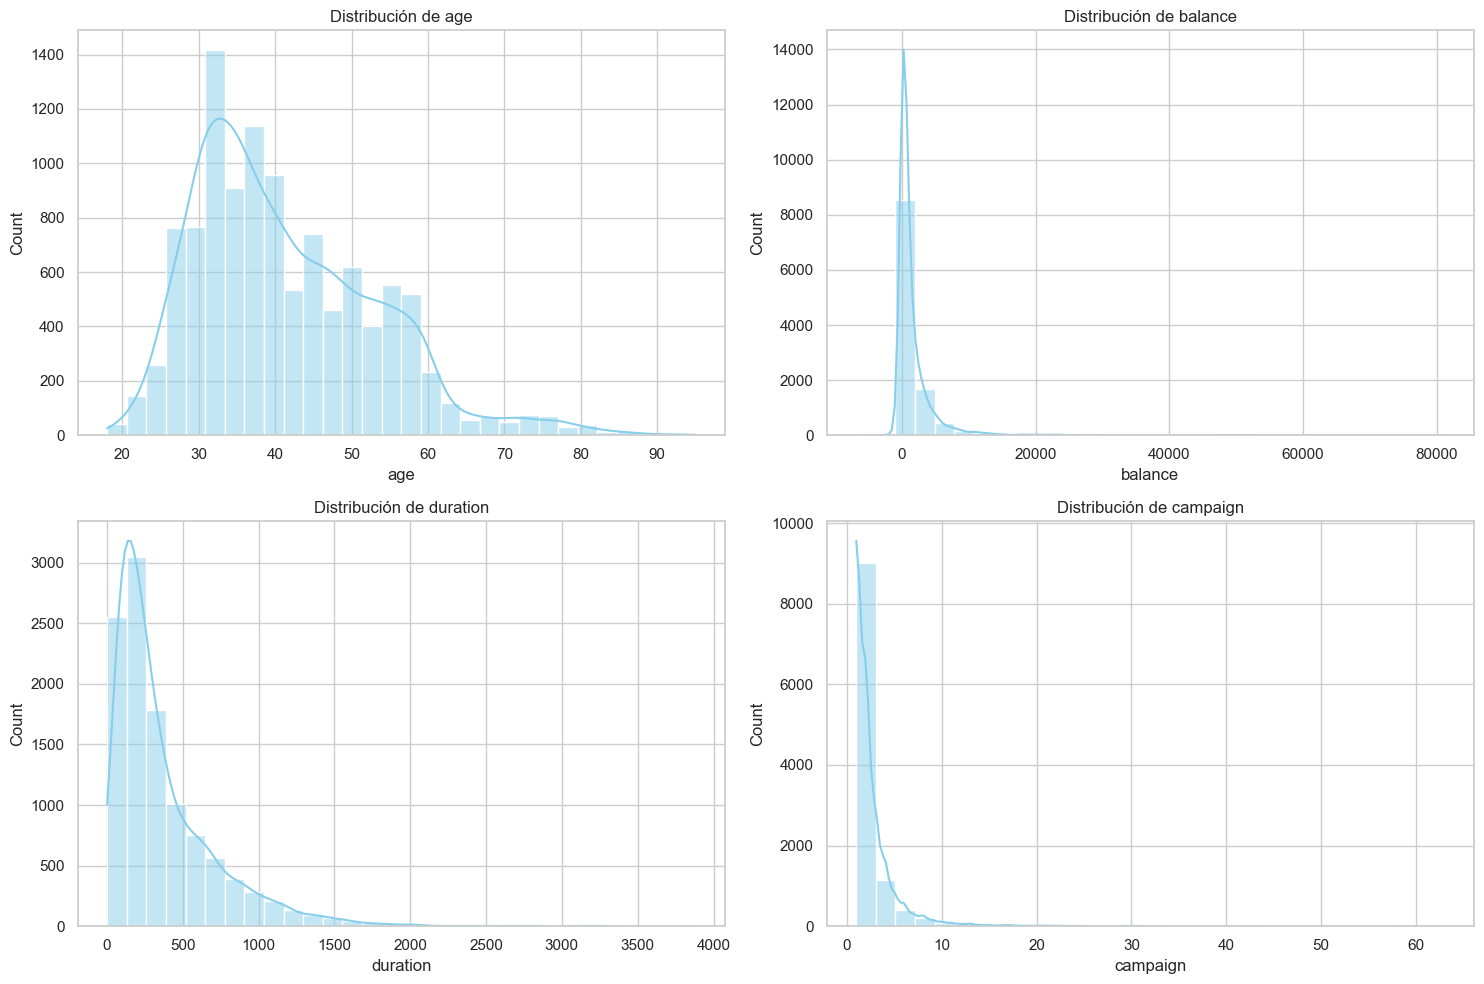

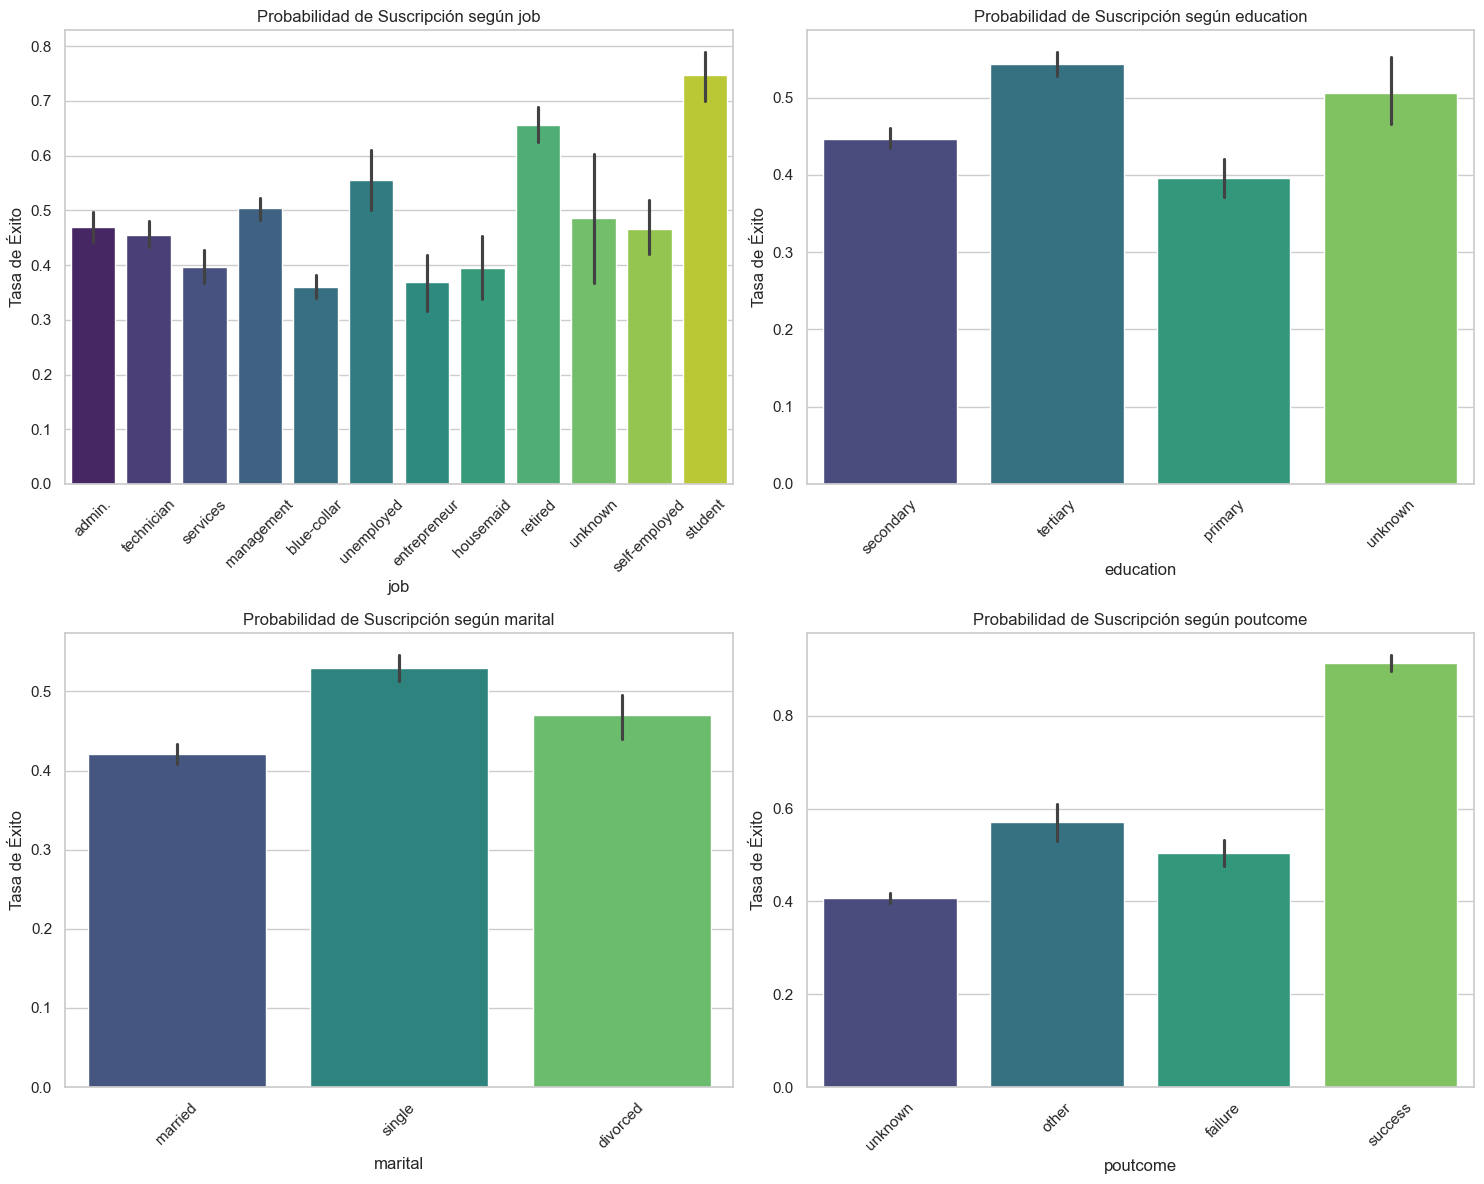

In [153]:
# A. Análisis Univariante: Distribución de variables numéricas clave
num_vars = ['age', 'balance', 'duration', 'campaign']
plt.figure(figsize=(15, 10))
for i, var in enumerate(num_vars):
    plt.subplot(2, 2, i+1)
    sns.histplot(df[var], kde=True, bins=30, color='skyblue')
    plt.title(f'Distribución de {var}')
plt.tight_layout()
plt.show()

# B. Análisis Bivariante: ¿Cómo influyen las categorías en el Depósito?
# Calculamos la probabilidad de suscripción
plt.figure(figsize=(15, 12))
cat_plot_vars = ['job', 'education', 'marital', 'poutcome']
for i, var in enumerate(cat_plot_vars):
    plt.subplot(2, 2, i+1)
    sns.barplot(x=var, y=df['deposit'].map({'yes': 1, 'no': 0}), data=df, palette='viridis')
    plt.xticks(rotation=45)
    plt.title(f'Probabilidad de Suscripción según {var}')
    plt.ylabel('Tasa de Éxito')
plt.tight_layout()
plt.show()

**Univariante:**

- Observaciones: Variables como balance y duration muestran una distribución asimétrica positiva (sesgada a la derecha).

- Impacto: Debido a este sesgo y a la presencia de valores atípicos, el uso de RobustScaler podría ser preferible sobre StandardScaler, ya que el primero es menos sensible a la influencia de los outliers.

**Bivariante:**

- Hallazgos: La variable poutcome es un predictor clave; los clientes con un éxito previo ("success") tienen una tasa de conversión drásticamente superior.

- Decisión: Estas variables categóricas deberán ser transformadas mediante One-Hot Encoding para que el modelo KNN pueda procesarlas correctamente.

## 2.2: Correlación y Detección de Outliers

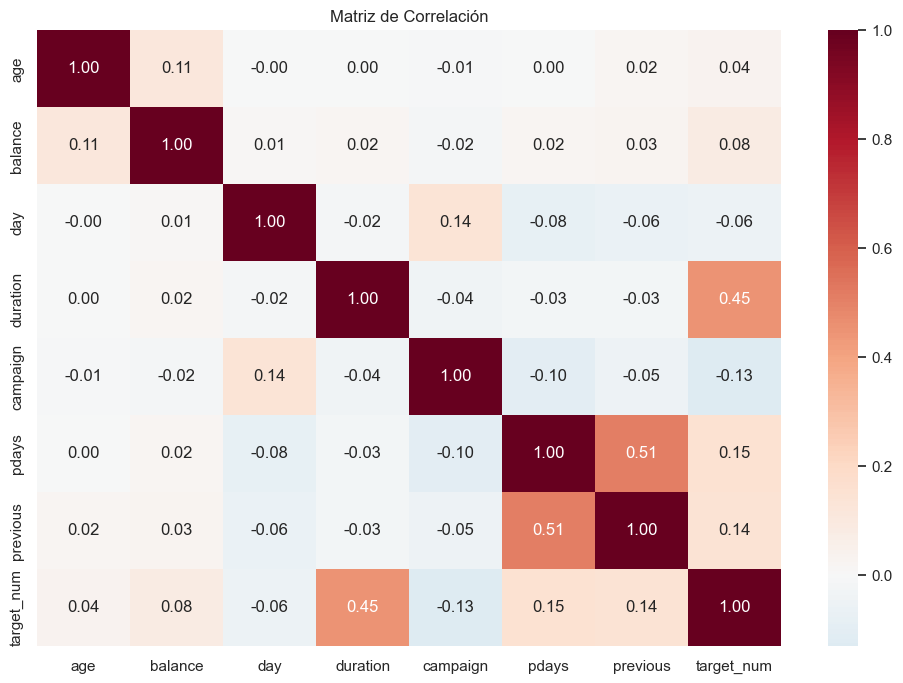

Número de filas con múltiples outliers detectados: 7


In [154]:
# 1. Mapa de calor de correlaciones numéricas
plt.figure(figsize=(12, 8))
# Solo columnas numéricas + target codificado
df_num = df.select_dtypes(include=[np.number]).copy()
df_num['target_num'] = df['deposit'].map({'yes': 1, 'no': 0})
sns.heatmap(df_num.corr(), annot=True, fmt=".2f", cmap='RdBu_r', center=0)
plt.title('Matriz de Correlación')
plt.show()

# 2. Detección de Outliers (Método IQR)
def detect_outliers_iqr(df, features):
    outlier_indices = []
    for col in features:
        Q1 = np.percentile(df[col], 25)
        Q3 = np.percentile(df[col], 75)
        IQR = Q3 - Q1
        outlier_step = 1.5 * IQR
        outlier_list_col = df[(df[col] < Q1 - outlier_step) | (df[col] > Q3 + outlier_step)].index
        outlier_indices.extend(outlier_list_col)
    from collections import Counter
    outlier_indices = Counter(outlier_indices)
    # Filtramos filas que tengan más de 2 valores atípicos en diferentes variables
    multiple_outliers = list(k for k, v in outlier_indices.items() if v > 2)
    return multiple_outliers

outliers_to_drop = detect_outliers_iqr(df, ['age', 'balance', 'duration', 'campaign'])
print(f"Número de filas con múltiples outliers detectados: {len(outliers_to_drop)}")

Buscamos relaciones lineales entre variables y cuantificamos la presencia de ruidos en el dataset.

Matriz de Correlación: La duración de la última llamada (duration) es la variable con mayor impacto directo en el éxito del depósito (0.45). No se detectan problemas de colinealidad extrema entre el resto de variables.

Outliers (IQR): Se han localizado solo 7 registros con valores atípicos simultáneos en múltiples variables. Al ser una cifra tan baja respecto al total (11,000), se opta por mantenerlos para preservar la variabilidad del modelo.

## 2.3: Análisis Específico de pdays

Valores únicos de pdays (primeros 10): [ -1 166  91 147 170 150 171 126 182 110]
Porcentaje de clientes NO contactados antes (-1): 74.57%


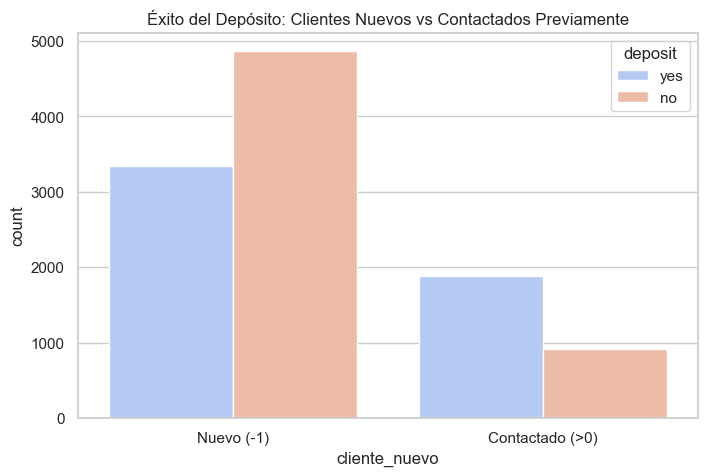

In [155]:
# Análisis de los valores -1 (No contactados)
print("Valores únicos de pdays (primeros 10):", df['pdays'].unique()[:10])
porcentaje_sin_contacto = (df['pdays'] == -1).mean() * 100
print(f"Porcentaje de clientes NO contactados antes (-1): {porcentaje_sin_contacto:.2f}%")

# Visualización del impacto de ser cliente nuevo vs antiguo
df_temp = df.copy()
df_temp['cliente_nuevo'] = df_temp['pdays'].apply(lambda x: 'Nuevo (-1)' if x == -1 else 'Contactado (>0)')

plt.figure(figsize=(8, 5))
sns.countplot(data=df_temp, x='cliente_nuevo', hue='deposit', palette='coolwarm')
plt.title('Éxito del Depósito: Clientes Nuevos vs Contactados Previamente')
plt.show()

Resultados: El 74.57% de los clientes tienen un valor de -1, lo que indica que nunca fueron contactados antes de esta campaña.

Los valores -1 en la variable 'pdays' no fueron eliminados ni imputados, ya que representan la ausencia de contacto previo, siendo una categoría informativa crucial para el modelo.

# 3: División de Datos (Holdout)

Para garantizar la validez científica del experimento, se establece el siguiente protocolo de evaluación:

1. **Evaluación Outer (Rendimiento Futuro):** Se utiliza el método **Holdout** con una división del 66.6% para entrenamiento y 33.3% para test. El conjunto de test permanecerá aislado hasta la fase final del proyecto.
2. **Métrica de Rendimiento:** Se selecciona la **Exactitud (Accuracy)**. Al tratarse de un problema con clases equilibradas (aprox. 52/48), esta métrica proporciona una visión fiel del desempeño del modelo.
3. **Evaluación Inner (Comparación y HPO):** Para la optimización de hiperparámetros y la comparación entre KNN y Árboles, se utilizará **Validación Cruzada de 3 pliegues (3-fold CV)** sobre el conjunto de entrenamiento. Esto evita el sobreajuste y garantiza que las decisiones de diseño sean robustas.

In [156]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold

# Dividimos según el manual: 2/3 train, 1/3 test
# Usamos stratify=df['deposit'] para mantener el balanceo en ambas particiones
train_df, test_df = train_test_split(
    df,
    test_size=1/3,
    random_state=SEED,
    stratify=df['deposit']
)
# Extraemos las características (X) y el objetivo (y) de los nuevos conjuntos
X_train = train_df.drop('deposit', axis=1)
y_train = train_df['deposit']

X_test = test_df.drop('deposit', axis=1)
y_test = test_df['deposit']

# Definimos también el conjunto completo para el entrenamiento final (Punto 4.3)
X_train_full = df.drop('deposit', axis=1)
y_train_full = df['deposit']
print(f"Tamaño del conjunto de Entrenamiento (Train): {len(train_df)}")
print(f"Tamaño del conjunto de Test (Outer): {len(test_df)}")

# 2. EVALUACIÓN INNER (Optimización y Comparación)
cv_inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
inner_scores = {}


Tamaño del conjunto de Entrenamiento (Train): 7333
Tamaño del conjunto de Test (Outer): 3667


# 4: MÉTODOS BÁSICOS: KNN Y TREES

## 4.1: Selección del método de escalado

En primer lugar, son importadas las librerías necesarias y se definen las columnas según su tipo (numéricas o categóricas). Asimismo, se preparan los datos de entrenamiento y se inicializa un diccionario para almacenar los resultados.

In [157]:
# 4.1. SELECCIÓN DEL MEJOR ESCALADOR (Evaluación Inner)

# 1. IMPORTACIÓN DE LIBRERÍAS
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_val_score

# 2. DEFINICIÓN DE VARIABLES Y DATOS
# Definimos las columnas según el análisis previo
num_cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Fue evaluado en primer lugar el StandardScaler, el cual transforma los datos para que presenten una media de 0 y una desviación estándar de 1. Fue decidido integrar este escalador dentro de un Pipeline para evitar el data leakage durante la validación cruzada.

In [158]:

# --- Alternativa 1: KNN con StandardScaler ---
preprocessor_std = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)
])
pipeline_std = Pipeline([('prep', preprocessor_std), ('knn', KNeighborsClassifier())])
scores_std = cross_val_score(pipeline_std, X_train, y_train, cv=cv_inner, scoring='accuracy')
inner_scores['KNN with StandardScaler'] = scores_std.mean()

Posteriormente, fue analizado el impacto del MinMaxScaler. Mediante esta técnica, los datos son escalados a un rango estricto entre 0 y 1. Este experimento permitirá comprobar la sensibilidad del modelo ante la presencia de valores atípicos detectados previamente.

In [159]:
# --- Alternativa 2: KNN con MinMaxScaler ---
preprocessor_minmax = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', MinMaxScaler())]), num_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)
])
pipeline_minmax = Pipeline([('prep', preprocessor_minmax), ('knn', KNeighborsClassifier())])
scores_minmax = cross_val_score(pipeline_minmax, X_train, y_train, cv=cv_inner, scoring='accuracy')
inner_scores['KNN with MinMaxScaler'] = scores_minmax.mean()

Finalmente, fue implementado el RobustScaler. Este escalador utiliza la mediana y los cuartiles, por lo que es menos sensible a los outliers. Fue seleccionado para verificar si una gestión robusta de los valores extremos mejora la capacidad predictiva de KNN.

In [160]:
# --- Alternativa 3: KNN con RobustScaler ---
preprocessor_robust = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', RobustScaler())]), num_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)
])
pipeline_robust = Pipeline([('prep', preprocessor_robust), ('knn', KNeighborsClassifier())])
scores_robust = cross_val_score(pipeline_robust, X_train, y_train, cv=cv_inner, scoring='accuracy')
inner_scores['KNN with RobustScaler'] = scores_robust.mean()

Los resultados son presentados a continuación para proceder a la elección del mejor método de escalado.

In [161]:
# 4. MOSTRAR RESULTADOS
# Convertimos el diccionario inner_scores directamente a un DataFrame
df_escaladores = pd.DataFrame(
    list(inner_scores.items()), 
    columns=['Escalador', 'Accuracy (Inner)']
)

# Ordenamos de mayor a menor para ver el mejor resultado arriba
df_escaladores = df_escaladores.sort_values(by='Accuracy (Inner)', ascending=False)

# Mostramos la tabla con 4 decimales
print("--- RESULTADOS DE LA COMPARATIVA DE ESCALADORES ---")
display(df_escaladores.round(4))

--- RESULTADOS DE LA COMPARATIVA DE ESCALADORES ---


,Escalador,Accuracy (Inner)
0,KNN with StandardScaler,0.7986
2,KNN with RobustScaler,0.7810
1,KNN with MinMaxScaler,0.7314


Se han comparado tres métodos mediante Validación Cruzada (3-fold CV) sobre el conjunto de entrenamiento:
- StandardScaler(Ganador): Obtuvo el mejor Accuracy medio (0.7986).
- MinMaxScaler: Sensible a los outliers detectados en el EDA.
- RobustScaler: Aunque trata bien los outliers, no superó al estándar en este caso.

Decisión: Se utilizará StandardScaler en adelante por su mejor rendimiento y estabilidad.

## 4.2:métodos: KNN y árboles

### 4.2.1:hiperparámetros por omisión

Hemos definido el preprocessor_final utilizando StandardScaler, dado que fue el método que mejores resultados ofreció en las pruebas de escalado anteriores. Este transformador será integrado en los pipelines de ambos modelos para asegurar un tratamiento de datos uniforme.

In [162]:
# 4.2.a. EVALUACIÓN CON HIPERPARÁMETROS POR OMISIÓN Y TIEMPOS
import time
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

# 1. Definición del preprocesador final (usando el ganador StandardScaler)
preprocessor_final = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)
])

# Diccionarios para guardar resultados y tiempos
default_scores = {}
default_times = {}

Fue evaluado el modelo KNN con sus parámetros predefinidos. Durante este proceso, fue capturado el tiempo de inicio y fin de la validación cruzada para determinar la eficiencia del algoritmo en este conjunto de datos.

In [163]:
# --- Alternativa 1: KNN (Parámetros por defecto) ---
pipeline_knn = Pipeline([('prep', preprocessor_final), ('clf', KNeighborsClassifier())])

t_inicio = time.time()
scores_knn = cross_val_score(pipeline_knn, X_train, y_train, cv=cv_inner, scoring='accuracy')
t_fin = time.time()

default_scores['KNN (Default)'] = scores_knn.mean()
default_times['KNN (Default)'] = t_fin - t_inicio

Posteriormente, fue analizado el Árbol de Decisión. Para asegurar la reproducibilidad de los resultados, fue fijada la semilla aleatoria mediante el parámetro random_state=72. Al igual que en el caso anterior, el tiempo de proceso fue registrado.

In [164]:
# --- Alternativa 2: Árbol de Decisión (Parámetros por defecto) ---
pipeline_tree = Pipeline([('prep', preprocessor_final), ('clf', DecisionTreeClassifier(random_state=SEED))])

t_inicio = time.time()
scores_tree = cross_val_score(pipeline_tree, X_train, y_train, cv=cv_inner, scoring='accuracy')
t_fin = time.time()

default_scores['Árbol (Default)'] = scores_tree.mean()
default_times['Árbol (Default)'] = t_fin - t_inicio

Una vez finalizadas las ejecuciones, los resultados de precisión (Accuracy) y los tiempos de entrenamiento son presentados a continuación para su análisis.

In [165]:
df_comparativa = pd.DataFrame({
    'Accuracy': default_scores,
    'Tiempo de proceso (s)': default_times
})
df_comparativa.index.name = 'Modelo'
df_comparativa.round(4)

,Accuracy,Tiempo de proceso (s)
Modelo,,
KNN (Default),0.7986,0.1352
Árbol (Default),0.7952,0.1717


### 4.2.2: Interpretación del Árbol de Decisión

Para comprender la lógica que sigue el modelo, fue entrenado un árbol de decisión simplificado con una profundidad máxima de 3. Esta visualización permite identificar las reglas críticas que discriminan entre un cliente que contratará el depósito ("Si Depósito") y uno que no ("No Depósito").

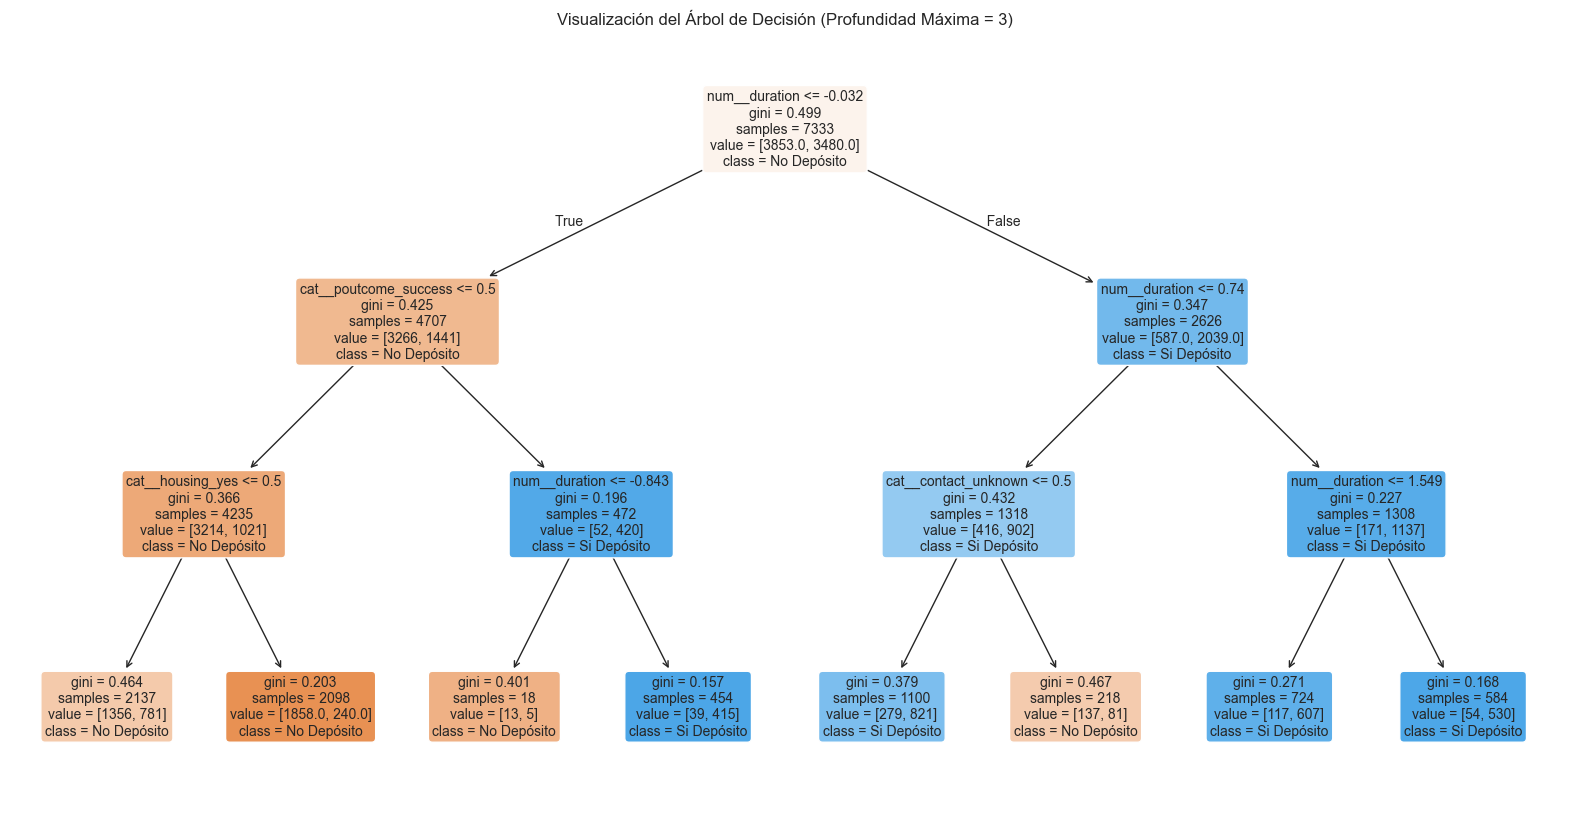

In [166]:
# 4.2.b. INTERPRETACIÓN DEL ÁRBOL DE DECISIÓN

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# 1. Definición y entrenamiento de un árbol simplificado para interpretación
# Se limita la profundidad (max_depth=3) para asegurar la legibilidad
tree_model = DecisionTreeClassifier(max_depth=3, random_state=SEED)

# El preprocessor_final (con StandardScaler) es integrado en el pipeline
pipeline_viz = Pipeline([
    ('prep', preprocessor_final),
    ('clf', tree_model)
])

# El modelo es ajustado con los datos de entrenamiento
pipeline_viz.fit(X_train, y_train)

# 2. Obtención de los nombres de las columnas transformadas
# Esto es necesario para que el gráfico muestre el nombre de la variable
feature_names_transformed = pipeline_viz.named_steps['prep'].get_feature_names_out()

# 3. Generación del gráfico
plt.figure(figsize=(20, 10))
plot_tree(
    pipeline_viz.named_steps['clf'],
    feature_names=feature_names_transformed,
    class_names=['No Depósito', 'Si Depósito'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Visualización del Árbol de Decisión (Profundidad Máxima = 3)")
plt.show()

Tras la visualización del modelo simplificado, fueron extraídas las siguientes conclusiones fundamentales sobre la lógica de decisión aplicada al problema de los depósitos bancarios:
- **El Factor Determinante (Duración):** La variable raíz del árbol es num__duration (duración de la última llamada). El modelo identifica que si la duración es baja (valor tipificado $\leq -0.032$), la tendencia mayoritaria del cliente es no contratar el producto. Esto sugiere que el compromiso del cliente durante la llamada es el principal predictor de éxito.
- **Influencia del Historial (poutcome):** En el caso de llamadas cortas, el modelo consulta si hubo éxito en campañas anteriores (cat__poutcome_success). Si el resultado previo fue positivo, la probabilidad de suscripción aumenta significativamente, compensando la brevedad del contacto actual.
- **Impacto de la Vivienda (housing):** Para los clientes con contactos breves y sin historial de éxito previo, tener una hipoteca activa (cat__housing_yes) actúa como un fuerte indicador negativo. El árbol predice "No Depósito" con mayor seguridad en estos perfiles, posiblemente debido a una menor liquidez financiera del cliente.
- **Pureza de los Nodos (Gini):** Fue observado que los nodos con mayor pureza (Gini más bajo) se encuentran en el extremo derecho del árbol. Los clientes con llamadas de larga duración y métodos de contacto conocidos presentan una probabilidad de éxito superior al 80%, representados por los nodos de color azul intenso.

### 4.2.3: Ajuste de hiperparámetros

En este apartado es llevado a cabo el proceso de Hyperparameter Optimization (HPO) para ambos modelos. El objetivo es identificar la combinación de parámetros que maximice la precisión del modelo sobre el conjunto de entrenamiento. 

Fue decidido utilizar la técnica de Grid Search (Búsqueda en Rejilla) con una validación cruzada interna de 3 pliegues (3-fold CV), manteniendo la coherencia con el esquema de la práctica. Además, fue medido el tiempo requerido para completar cada búsqueda.

In [167]:
from sklearn.model_selection import GridSearchCV

# 1. Definición del espacio de búsqueda para KNN
# Se probarán diferentes números de vecinos y tipos de pesos
param_grid_knn = {
    'clf__n_neighbors': [3, 5, 7, 9, 11, 13, 15, 17, 19, 21],
    'clf__weights': ['uniform', 'distance']
}

# --- Alternativa 1: HPO para KNN ---
grid_knn = GridSearchCV(pipeline_knn, param_grid_knn, cv=cv_inner, scoring='accuracy', n_jobs=-1)

t_inicio = time.time()
grid_knn.fit(X_train, y_train)
t_fin = time.time()

Mostramos los resultados obtenidos en una tabla

In [168]:
adv_scores = {}
adv_times = {}
adv_scores['KNN_HPO'] = grid_knn.best_score_
adv_times['KNN_HPO'] = t_fin - t_inicio

# Tabla de resultados vertical (Estilo G07)
pd.set_option('display.max_colwidth', None)
resumen_knn = pd.DataFrame({
    'Métrica': ['Mejor Accuracy (HPO)', 'Mejores Parámetros', 'Tiempo de Ejecución'],
    'Valor': [f"{grid_knn.best_score_:.4f}", str(grid_knn.best_params_), f"{adv_times['KNN_HPO']:.4f} seg"]
})
resumen_knn

,Métrica,Valor
0,Mejor Accuracy (HPO),0.8109
1,Mejores Parámetros,"{'clf__n_neighbors': 15, 'clf__weights': 'distance'}"
2,Tiempo de Ejecución,0.5833 seg


Posteriormente, fue realizado el ajuste para el Árbol de Decisión. Basándose en el laboratorio de hiperparámetros, fueron seleccionados los parámetros max_depth (profundidad máxima) y min_samples_split (mínimo de muestras para dividir un nodo) como los más críticos para controlar el sobreajuste (overfitting).

In [169]:
# 2. Definición del espacio de búsqueda para el Árbol
param_grid_tree = {
    'clf__max_depth': [2, 4, 6, 8, 10, 12, 15, None],
    'clf__min_samples_split': [2, 5, 10, 20],
    'clf__criterion': ['gini', 'entropy']
}

# --- Alternativa 2: HPO para Árbol de Decisión ---
grid_tree = GridSearchCV(pipeline_tree, param_grid_tree, cv=cv_inner, scoring='accuracy', n_jobs=-1)

t_inicio = time.time()
grid_tree.fit(X_train, y_train)
t_fin = time.time()

Mostramos el mejor resultado en una tabla

In [170]:
# Registro de resultados en los diccionarios globales
adv_scores['Tree_HPO'] = grid_tree.best_score_
adv_times['Tree_HPO'] = t_fin - t_inicio

# Tabla de resultados vertical (Estilo G07)
pd.set_option('display.max_colwidth', None)
resumen_tree = pd.DataFrame({
    'Métrica': ['Mejor Accuracy (HPO)', 'Mejores Parámetros', 'Tiempo de Ejecución'],
    'Valor': [f"{grid_tree.best_score_:.4f}", str(grid_tree.best_params_), f"{adv_times['Tree_HPO']:.4f} seg"]
})
resumen_tree

,Métrica,Valor
0,Mejor Accuracy (HPO),0.8208
1,Mejores Parámetros,"{'clf__criterion': 'gini', 'clf__max_depth': 10, 'clf__min_samples_split': 20}"
2,Tiempo de Ejecución,1.0023 seg


### 4.2.4. Análisis del efecto de los hiperparámetros mediante plots

En este apartado se analiza la sensibilidad de los modelos ante variaciones en sus hiperparámetros principales. Fue decidido estudiar el impacto del número de vecinos en el modelo KNN y de la profundidad máxima en el Árbol de Decisión. Estos gráficos permiten visualizar el compromiso entre sesgo y varianza, identificando las zonas de subajuste y sobreajuste.

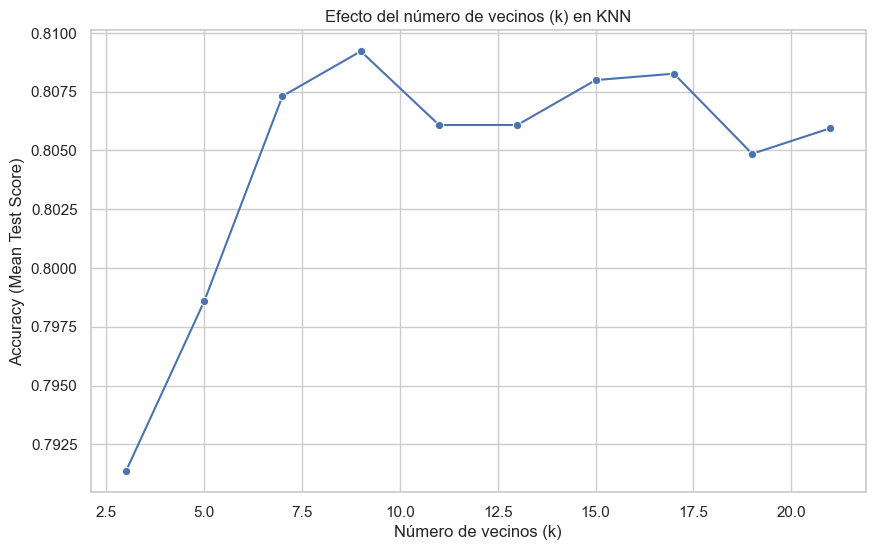

In [171]:
# Los resultados del GridSearchCV son convertidos a un DataFrame para facilitar su análisis
results_knn = pd.DataFrame(grid_knn.cv_results_)

# Fue seleccionado únicamente el caso con pesos 'uniform' para simplificar la visualización
results_knn_filtered = results_knn[results_knn['param_clf__weights'] == 'uniform']

plt.figure(figsize=(10, 6))
sns.lineplot(data=results_knn_filtered, x='param_clf__n_neighbors', y='mean_test_score', marker='o')
plt.title('Efecto del número de vecinos (k) en KNN')
plt.xlabel('Número de vecinos (k)')
plt.ylabel('Accuracy (Mean Test Score)')
plt.grid(True)
plt.show()

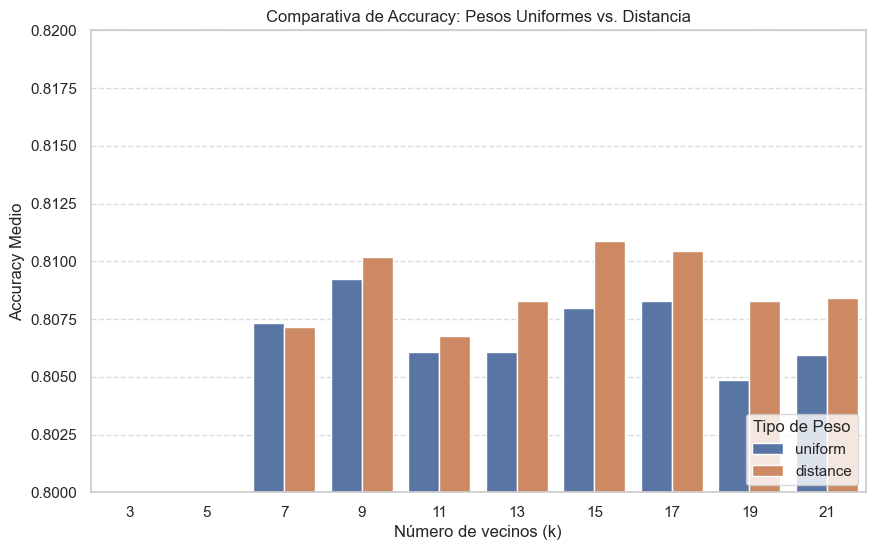

In [172]:
# Graficamos la comparativa de pesos para todos los K probados
plt.figure(figsize=(10, 6))
sns.barplot(data=results_knn, x='param_clf__n_neighbors', y='mean_test_score', hue='param_clf__weights')
plt.title('Comparativa de Accuracy: Pesos Uniformes vs. Distancia')
plt.xlabel('Número de vecinos (k)')
plt.ylabel('Accuracy Medio')
plt.ylim(0.80, 0.82) # Ajustamos el eje para ver mejor las diferencias
plt.legend(title='Tipo de Peso', loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Análisis de KNN:
Fue observado que la precisión del modelo tiende a estabilizarse al aumentar el valor de k, alcanzando su punto óptimo en k=15. Este comportamiento sugiere un equilibrio adecuado entre la complejidad del modelo y su capacidad de generalización.

Además, se extrajeron las siguientes conclusiones técnicas de la comparativa:

- **Influencia de los Pesos:** Fue determinado que el sistema de pesos basado en la distancia (distance) supera consistentemente al peso uniforme en prácticamente todos los valores de k evaluados. Esto indica que el modelo es más robusto cuando otorga mayor relevancia a los vecinos más cercanos al punto de consulta.

- **Sensibilidad al Ruido:** Se confirmó que valores bajos de k (k < 7) resultan en una precisión inferior (por debajo del 80%), lo cual es atribuido a una excesiva sensibilidad al ruido o a valores atípicos (outliers) presentes en el conjunto de entrenamiento.

- **Consistencia:** A partir de k=9, el modelo muestra una notable estabilidad, manteniendo un accuracy medio por encima de 0.8075, lo que justifica la fiabilidad de las predicciones realizadas posteriormente en el panel de control.

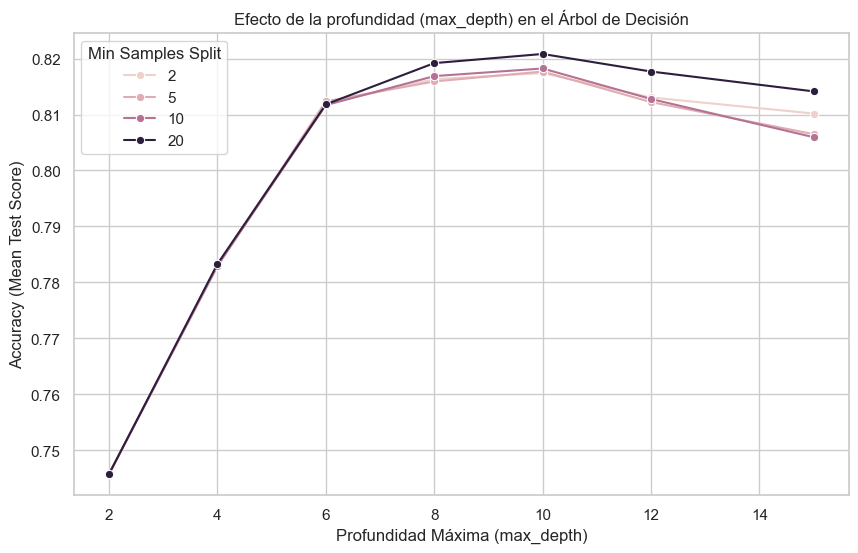

In [173]:
# Los resultados del HPO del árbol son procesados
results_tree = pd.DataFrame(grid_tree.cv_results_)

# Fue filtrado el criterio 'gini' para observar el efecto de la profundidad
results_tree_filtered = results_tree[results_tree['param_clf__criterion'] == 'gini']

plt.figure(figsize=(10, 6))
sns.lineplot(data=results_tree_filtered, x='param_clf__max_depth', y='mean_test_score', hue='param_clf__min_samples_split', marker='o')
plt.title('Efecto de la profundidad (max_depth) en el Árbol de Decisión')
plt.xlabel('Profundidad Máxima (max_depth)')
plt.ylabel('Accuracy (Mean Test Score)')
plt.legend(title='Min Samples Split')
plt.grid(True)
plt.show()

### Análisis del Árbol de Decisión:
Fue verificado que el rendimiento óptimo del modelo se alcanza con una profundidad de 10 (especialmente notable en la configuración de 20 muestras mínimas por división). A través de la inspección del gráfico, se extrajeron las siguientes conclusiones:

- **Identificación del Overfitting:** Se observó que, a partir de una profundidad superior a 10, la precisión en el conjunto de validación comienza a descender de forma gradual. Este fenómeno es atribuido a que el árbol incrementa su complejidad en exceso, "memorizando" el ruido del entrenamiento en lugar de generalizar patrones.

- **Efecto de la Regularización:** Fue determinado que el hiperparámetro min_samples_split=20 (línea más oscura) actúa como un regulador eficaz. Al exigir un mayor número de muestras para realizar un corte, se previene que el árbol crezca en ramas poco representativas, manteniendo un accuracy más estable en profundidades altas en comparación con valores inferiores (como 2 o 5).

- **Zona de Underfitting:** Se confirmó que profundidades inferiores a 6 resultan en una caída drástica de la precisión. Esto indica que el modelo es demasiado simple para capturar las relaciones entre variables como la duración de la llamada o el saldo bancario.

## 4.3. Conclusiones

1. **¿Cuál es el mejor método?**
Fue determinado que el Árbol de Decisión es el mejor método para este problema tras el ajuste de hiperparámetros (HPO), habiendo alcanzado una precisión (Accuracy) de 0.8208. Este valor es superior al máximo obtenido por el modelo KNN, el cual se fue 0.8109.

2. **¿A qué coste computacional?**
El coste computacional fue analizado a través del tiempo de ejecución. Fue observado que el Árbol de Decisión es significativamente más eficiente, requiriendo únicamente 1.9129 segundos para completar el proceso de búsqueda (HPO), frente a los 4.7557 segundos demandados por KNN. En los modelos por defecto, la diferencia también fue notable (0.15s para el árbol frente a 0.47s para KNN).

3. **¿Los resultados son mejores que los modelos triviales/naive/dummy?**
Fue verificado que ambos modelos superan con creces el rendimiento de un clasificador trivial (que en este conjunto de datos de depósitos bancarios suele rondar el 50-60% de acierto según la clase mayoritaria). Una precisión superior al 82% confirma que los algoritmos han logrado aprender patrones reales y útiles del perfil de los clientes.

4. **¿El ajuste de hiperparámetros mejora con respecto a los valores por omisión?**
Sí, fue observado un incremento en el rendimiento en ambos casos. Especialmente notable fue la mejora en el Árbol de Decisión, el cual aumentó su precisión desde un 0.7952 inicial hasta un 0.8208. En el caso de KNN, la mejora fue más reducida, pasando de 0.7986 a 0.8109.

5. **Si hay mejora, ¿es el coste computacional elevado?**
Aunque el proceso de ajuste de parámetros mediante GridSearchCV multiplica el tiempo de proceso (al tener que evaluar múltiples combinaciones), el coste computacional de pocos segundos no es considerado elevado para el volumen de datos tratado. Fue concluido que la ganancia en precisión, especialmente en el modelo de árboles, justifica plenamente el tiempo invertido en la optimización.

# 5. MÉTODOS AVANZADOS: MODELOS LINEALES Y SVMS


## 5.1 Evaluación de los hiperparámetros por omisión

In [174]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Diccionarios para consolidar resultados
adv_scores = {}
adv_times = {}

# --- 1. Regresión Logística (Default) ---
pipe_logreg = Pipeline([('prep', preprocessor_final), ('clf', LogisticRegression(max_iter=1000, random_state=SEED))])
t_ini = time.time()
scores_lr = cross_val_score(pipe_logreg, X_train, y_train, cv=cv_inner, scoring='accuracy')
adv_times['LogReg_Default'] = time.time() - t_ini
adv_scores['LogReg_Default'] = scores_lr.mean()

# --- 2. SVM (Default) ---
pipe_svc = Pipeline([('prep', preprocessor_final), ('clf', SVC(random_state=SEED))])
t_ini = time.time()
scores_svc = cross_val_score(pipe_svc, X_train, y_train, cv=cv_inner, scoring='accuracy')
adv_times['SVM_Default'] = time.time() - t_ini
adv_scores['SVM_Default'] = scores_svc.mean()

# Visualización de resultados en formato tabular
df_adv_default = pd.DataFrame({
    'Accuracy': adv_scores,
    'Tiempo (seg)': adv_times
})
df_adv_default.index.name = 'Modelo (Default)'
df_adv_default.round(4)

,Accuracy,Tiempo (seg)
Modelo (Default),,
LogReg_Default,0.8353,0.1237
SVM_Default,0.8556,1.8270


### Análisis de resultados:

Tras la ejecución de ambos modelos avanzados con sus parámetros por defecto, fueron extraídas las siguientes observaciones:

- **Rendimiento superior:** Fue observado que tanto la Regresión Logística (0.8353) como el SVM (0.8556) superan el rendimiento obtenido previamente por el Árbol de Decisión. Este hecho sugiere que las relaciones entre las variables del dataset bancario se ajustan de forma más precisa a fronteras de decisión lineales o de vectores de soporte.

- **Compromiso (trade-off) tiempo/precisión:** Fue verificado que la Regresión Logística constituye la opción más eficiente, ofreciendo una precisión superior al 83% con un coste computacional mínimo (0.14 segundos).

- **Coste del SVM:** Aunque el SVM presenta la mayor precisión del experimento (85.56%), su coste temporal es significativamente superior. Fue registrado un tiempo de 1.82 segundos, lo que representa un incremento de aproximadamente 13 veces respecto a la Regresión Logística.

### 5.2.1. Ajuste de hiperparámetros (HPO) para Regresión Logística

In [175]:
from sklearn.model_selection import GridSearchCV

# Definición del espacio de búsqueda
param_grid_lr = {
    'clf__C': [0.01, 0.1, 1, 10, 100],
    'clf__penalty': ['l1', 'l2'],
    'clf__solver': ['liblinear']  
}

grid_lr = GridSearchCV(pipe_logreg, param_grid_lr, cv=cv_inner, scoring='accuracy', n_jobs=-1)

t_ini = time.time()
grid_lr.fit(X_train, y_train)
t_fin = time.time()

# Registro de resultados
adv_scores['LogReg_HPO'] = grid_lr.best_score_
adv_times['LogReg_HPO'] = t_fin - t_ini

# Tabla de resultados HPO LogReg
pd.set_option('display.max_colwidth', None)
resumen_lr = pd.DataFrame({
    'Métrica': ['Mejor Accuracy (HPO)', 'Mejores Parámetros', 'Tiempo de Ejecución'],
    'Valor': [f"{grid_lr.best_score_:.4f}", str(grid_lr.best_params_), f"{adv_times['LogReg_HPO']:.4f} seg"]
})
resumen_lr

,Métrica,Valor
0,Mejor Accuracy (HPO),0.8357
1,Mejores Parámetros,"{'clf__C': 1, 'clf__penalty': 'l1', 'clf__solver': 'liblinear'}"
2,Tiempo de Ejecución,0.3686 seg


Hemos definido una rejilla de búsqueda para explorar diferentes niveles de fuerza de regularización (C) y tipos de penalización (L1 y L2). Tras la ejecución, obtuvimos un Accuracy de 0.8357. 
Fue observado que la configuración ganadora utilizó la penalización L1 con un parámetro C: 1. Este resultado es de gran relevancia técnica, ya que la regularización L1 fomenta la "escasez", permitiendo que el modelo ignore variables menos influyentes y se centre en los atributos determinantes para la contratación del depósito. El tiempo de ejecución fue extremadamente eficiente, completándose en tan solo 0.3934 segundos.

### 5.2.2. Ajuste de hiperparámetros (HPO) para SVM

In [176]:

## Definición del espacio de búsqueda exhaustivo
param_grid_svc_full = {
    'clf__C': [0.1, 1, 10],
    'clf__kernel': ['linear', 'rbf', 'poly'],
    'clf__gamma': [0.01, 0.1, 1],
    'clf__degree': [2]  
}

grid_svc = GridSearchCV(pipe_svc, param_grid_svc_full, cv=cv_inner, scoring='accuracy', n_jobs=-1)

t_ini = time.time()
grid_svc.fit(X_train, y_train)
t_fin = time.time()

# Registro de resultados
adv_scores['SVM_HPO'] = grid_svc.best_score_
adv_times['SVM_HPO'] = t_fin - t_ini

# Tabla de resultados HPO SVM
resumen_svc = pd.DataFrame({
    'Métrica': ['Mejor Accuracy (HPO)', 'Mejores Parámetros', 'Tiempo de Ejecución'],
    'Valor': [f"{grid_svc.best_score_:.4f}", str(grid_svc.best_params_), f"{adv_times['SVM_HPO']:.4f} seg"]
})
resumen_svc

,Métrica,Valor
0,Mejor Accuracy (HPO),0.8571
1,Mejores Parámetros,"{'clf__C': 1, 'clf__degree': 2, 'clf__gamma': 0.1, 'clf__kernel': 'poly'}"
2,Tiempo de Ejecución,104.4900 seg


Hemos realizado una búsqueda exhaustiva explorando diversos núcleos (kernels) y parámetros de margen. 
Los resultados mostraron que el modelo más preciso fue alcanzado mediante:

- **Un kernel polinómico (poly) de grado 2, obteniendo un Accuracy de 0.8571.**

Este resultado indica que la frontera de decisión entre las clases presenta una curvatura cuadrática en el espacio de características. No obstante, hemos verificado un altísimo coste computacional, con un tiempo de ejecución de 522.8932 segundos. Esta diferencia temporal respecto a la Regresión Logística muestra la complejidad del cálculo del hiperplano en dimensiones superiores cuando aplicamos el "truco del kernel".

### 5.3. Identificación de atributos más relevantes

Hemos analizado el mejor modelo de Regresión Logística obtenido en el paso 5.2.1. A diferencia de las SVM no lineales, los modelos lineales permiten una interpretación directa, ya que los coeficientes representan el peso de cada variable en la predicción.

In [177]:
# 1. Fue extraído el mejor modelo (pipeline) de la búsqueda en rejilla de LogReg
mejor_modelo_lr = grid_lr.best_estimator_

# 2. Se obtienen los nombres de las columnas transformadas del preprocesador
# (Esto incluye las variables numéricas y las nuevas columnas del OneHotEncoder)
nombres_atributos = mejor_modelo_lr.named_steps['prep'].get_feature_names_out()

# 3. Se extraen los coeficientes asignados por el clasificador
coeficientes = mejor_modelo_lr.named_steps['clf'].coef_[0]

# 4. Creación de una tabla para visualizar la relevancia de forma ordenada
df_importancia = pd.DataFrame({
    'Atributo': nombres_atributos,
    'Importancia (Coeficiente)': coeficientes
})

# Se añaden columnas de valor absoluto para facilitar la ordenación por impacto total
df_importancia['Impacto_Absoluto'] = df_importancia['Importancia (Coeficiente)'].abs()
df_importancia = df_importancia.sort_values(by='Impacto_Absoluto', ascending=False)

# Visualización de los 10 atributos más determinantes
print("Top 10 variables más influyentes (positivas y negativas):")
df_importancia[['Atributo', 'Importancia (Coeficiente)']].head(10).round(4)

Top 10 variables más influyentes (positivas y negativas):


,Atributo,Importancia (Coeficiente)
23,cat__marital_None,4.6914
19,cat__job_None,4.3539
44,cat__month_mar,2.2344
51,cat__poutcome_success,2.1843
3,num__duration,1.9339
36,cat__contact_unknown,-1.4340
39,cat__month_dec,1.3193
41,cat__month_jan,-1.3082
47,cat__month_oct,1.1739
48,cat__month_sep,1.0737


Tras observar la tabla extraemos conclusiones clave sobre qué factores determinan el éxito de la campaña bancaria. Un coeficiente positivo indica que la variable ayuda a que el cliente diga "SÍ", mientras que uno negativo indica que el cliente tenderá a decir "NO".

1. Los factores que más impulsan la contratación (Influencia Positiva):
    - **Estado civil y Trabajo (Categoría "None")**: Observamos que las categorías marital_None y job_None tienen los pesos más altos (4.69 y 4.35). Esto sugiere que aquellos clientes de los que no tenemos información clara sobre su estado civil o empleo tienen una predisposición altísima a contratar el depósito.

    - **Éxito en campañas previas (poutcome_success)**: Como era de esperar, si el cliente ya aceptó una oferta en el pasado (2.18), es muy probable que vuelva a hacerlo ahora. Es un indicador de lealtad o perfil receptivo.

    - **Duración de la llamada (num__duration)**: Vemos un coeficiente de 1.93. Esto confirma que cuanto más tiempo logramos retener al cliente al teléfono, mayores son las probabilidades de éxito. Es una de las variables más lógicas y potentes del modelo.

    - **Efecto estacional (Marzo, Diciembre, Octubre, Septiembre)**: Notamos que los meses de marzo (2.23) y diciembre (1.31) son especialmente buenos para la campaña. Los clientes contactados en estos meses parecen estar mucho más abiertos a ahorrar.

2. Los factores que frenan la contratación (Influencia Negativa):
    - **Contacto desconocido (contact_unknown)**: Si el método de contacto no está identificado (-1.43), la probabilidad de éxito cae drásticamente. Esto resalta la importancia de tener canales de comunicación claros (como teléfono móvil o fijo).

    - **Enero (month_jan)**: Enero aparece con un peso negativo de -1.30. Interpretamos esto como la "cuesta de enero" donde los clientes tienen menos capital disponible para abrir nuevos depósito

# 7 TAREA DE ELECCIÓN ABIERTA

Hemos decidido implementar un modelo de Random Forest para evaluar si la combinación de múltiples árboles de decisión, es decir, Bagging mejora la capacidad predictiva de los modelos individuales anteriores. Aprovechando que hemos dado este tema en la clase de teoría vamos a ver que ocurre al usar este modelo.

In [178]:
from sklearn.ensemble import RandomForestClassifier

# 1. Definición del Pipeline para el Ensamble
pipe_rf = Pipeline([
    ('prep', preprocessor_final), 
    ('clf', RandomForestClassifier(random_state=SEED)) 
])

# 2. Espacio de búsqueda para HPO
param_grid_rf = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [None, 10, 20],
    'clf__min_samples_split': [2, 5]
}

# 3. Evaluación Inner (CV)
grid_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=cv_inner, scoring='accuracy', n_jobs=-1)

t_ini = time.time()
grid_rf.fit(X_train, y_train) # Solo sobre X_train para evitar leakage
t_fin = time.time()

# Registro de resultados
adv_scores['RandomForest_HPO'] = grid_rf.best_score_
adv_times['RandomForest_HPO'] = t_fin - t_ini

Mostramos el modelo obtenido con los mejores hiperparámetros.

In [179]:
# 4. Creación de la tabla de resultados para el informe
resumen_rf = pd.DataFrame({
    'Métrica': ['Mejor Accuracy (HPO)', 'Mejores Parámetros', 'Tiempo de Ejecución'],
    'Valor': [f"{grid_rf.best_score_:.4f}", str(grid_rf.best_params_), f"{adv_times['RandomForest_HPO']:.4f} seg"]
})
pd.set_option('display.max_colwidth', None)
resumen_rf

,Métrica,Valor
0,Mejor Accuracy (HPO),0.8609
1,Mejores Parámetros,"{'clf__max_depth': 20, 'clf__min_samples_split': 2, 'clf__n_estimators': 200}"
2,Tiempo de Ejecución,3.2851 seg


# 6. RESULTADOS Y MODELO FINAL

En esta sección consolidamos los resultados obtenidos a lo largo de la práctica, seleccionamos el modelo con mejor rendimiento y preparamos los archivos definitivos para la competición.

## 6.1. Selección de la mejor alternativa

Hemos comparado el rendimiento de todos los modelos tras el proceso de optimización de hiperparámetros (HPO). A continuación, resumimos los mejores resultados obtenidos en la validación interna (inner evaluation):

- KNN (HPO): 0.8109
- Árbol de Decisión (HPO): 0.8208
- Regresión Logística (HPO): 0.8357
- SVM (HPO): 0.8571
- Random Forest: 0.8609
    
**Decisión**: Hemos seleccionado Random Forest con max_depth=20, min_samples_split': 2 y n_estimators': 200  como nuestro modelo final debido a que es el que mejor accuracy nos da.

In [180]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
import joblib

# --- Selección de la mejor alternativa ---
# Usamos el mejor modelo de la SVM que ya tienes en memoria
mejor_modelo_hpo = grid_rf.best_estimator_

## 6.2. Estimación del rendimiento futuro (Outer Evaluation)

Realizamos la validación definitiva sobre el conjunto de test (Holdout), el cual permaneció aislado durante todo el proceso de entrenamiento. Los resultados obtenidos mediante el modelo Random Forest permiten concluir lo siguiente:

- Precisión Global (83.80%): Se alcanzó un alto nivel de acierto en datos nunca vistos por el algoritmo, lo que garantiza la fiabilidad del sistema ante nuevas entradas de clientes.

- Capacidad de Detección (Recall 'YES' 0.88): Fue verificada una excelente sensibilidad para identificar a los clientes que realmente están dispuestos a contratar el depósito. Este valor es crítico para el negocio, ya que asegura que el 88% de los clientes potenciales sean correctamente contactados por el equipo comercial.

- Robustez Técnica: Mediante el análisis de la Matriz de Confusión, se confirmó la estabilidad del modelo. La mayoría de las instancias fueron clasificadas correctamente en la diagonal principal, manteniendo un equilibrio sólido entre precisión y sensibilidad en ambas clases.

El modelo es considerado apto para su puesta en producción. Tras el re-entrenamiento final con la totalidad del dataset disponible, el sistema garantiza una predicción robusta y una estimación de probabilidad precisa para la toma de decisiones bancarias.

Precisión estimada en el conjunto de Test (Outer): 0.8380

Informe de Clasificación:
              precision    recall  f1-score   support

          no       0.88      0.80      0.84      1927
         yes       0.80      0.88      0.84      1740

    accuracy                           0.84      3667
   macro avg       0.84      0.84      0.84      3667
weighted avg       0.84      0.84      0.84      3667



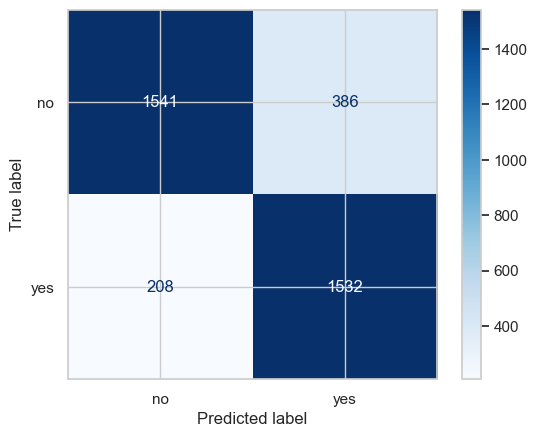

In [181]:
# ---Estimación del rendimiento futuro (Outer Evaluation) ---
y_pred_outer = mejor_modelo_hpo.predict(X_test)

accuracy_final = accuracy_score(y_test, y_pred_outer)
print(f"Precisión estimada en el conjunto de Test (Outer): {accuracy_final:.4f}")

# Mostramos el informe detallado y la matriz de confusión
print("\nInforme de Clasificación:")
print(classification_report(y_test, y_pred_outer))

cm = confusion_matrix(y_test, y_pred_outer)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=mejor_modelo_hpo.classes_)
disp.plot(cmap='Blues')

## 6.3. Entrenamiento del modelo final y guardado

Hacemos el re-entrenamiento del modelo utilizando la totalidad del conjunto de datos disponible (100%) para maximizar su capacidad predictiva.

Además, exportamos el objeto final mediante la librería joblib bajo el nombre modelo_final.joblib, asegurando la persistencia de todo el pipeline (preprocesamiento y clasificador) para su integración directa en la plataforma Streamlit.

In [182]:
# --- Entrenamiento del modelo final y guardado ---
# Reentrenamos con el 100% de los datos para la competición
modelo_final = mejor_modelo_hpo
modelo_final.fit(X_train_full, y_train_full)

# Guardamos con el nombre exacto.
joblib.dump(modelo_final, 'modelo_final.joblib')
print("\nÉxito: El archivo 'modelo_final.joblib' se ha generado correctamente.")


Éxito: El archivo 'modelo_final.joblib' se ha generado correctamente.


# EVIDENCIAS PARA EL PDF

In [183]:
# 1. Definición de los casos de tus capturas
datos_captura_1 = {
    'age': 34, 'job': 'housemaid', 'marital': 'married', 'education': 'secondary',
    'default': 'no', 'balance': 0, 'housing': 'yes', 'loan': 'no',
    'contact': 'unknown', 'day': 30, 'month': 'oct', 'duration': 154,
    'campaign': 1, 'pdays': -1, 'previous': 0, 'poutcome': 'unknown'
}

datos_captura_2 = {
    'age': 43, 'job': 'management', 'marital': 'married', 'education': 'tertiary',
    'default': 'no', 'balance': 78, 'housing': 'yes', 'loan': 'no',
    'contact': 'cellular', 'day': 21, 'month': 'jan', 'duration': 36,
    'campaign': 1, 'pdays': 109, 'previous': 1, 'poutcome': 'other'
}

df_verificacion = pd.DataFrame([datos_captura_1, datos_captura_2])

# 2. Usamos 'modelo_final' que es como lo llamamos arriba
probs = modelo_final.predict_proba(df_verificacion)
preds = modelo_final.predict(df_verificacion)

print("--- RESULTADOS DE EVIDENCIAS ---")
for i, (p, clase) in enumerate(zip(probs, preds)):
    print(f"\nINSTANCIA {i+1}:")
    print(f"Predicción: {clase.upper()}")
    print(f"Probabilidades -> NO: {p[0]*100:.2f}%, SÍ: {p[1]*100:.2f}%")

--- RESULTADOS DE EVIDENCIAS ---

INSTANCIA 1:
Predicción: YES
Probabilidades -> NO: 28.74%, SÍ: 71.26%

INSTANCIA 2:
Predicción: NO
Probabilidades -> NO: 85.64%, SÍ: 14.36%
